# 06 — Tuned CatBoost and XGBoost daily forecasts

Checkpoint 4 compares **CatBoost and XGBoost** with the tuned 61-feature LightGBM daily recipe. Each challenger searches four configurations within historical training and validation periods. Every final forecast is evaluated on the same eligible stock-days, with the same daily sources, median-relative log target, preprocessing, sample caps and reconstruction bounds.

The CatBoost grid reproduces Alisa's completed experiment. XGBoost is a new experiment. The LightGBM reference reuses its previously selected historical configurations and tree counts, refitting on the same rows as both challengers. The two new searches have four configurations each, while the historical LightGBM selection searched eight. The comparison reflects those complete research procedures.

This notebook runs the full four-year study. It records fitting samples, models, predictions, validation curves and checks under `outputs/experiments/28_daily_booster_comparison`, allowing later reuse and verified restart. The master folder contains the numbered narrative notebooks. The executed tables and figures below are embedded for review.

Run in the repository's Python environment with the EDA/model dependencies plus CatBoost and XGBoost. The complete CPU run can take substantial time. Completed folds and validation trials are reused only after checking the experiment plan and sample fingerprints. Results determine the conclusion at the end of this notebook.

In [1]:
from pathlib import Path
import sys
import tempfile
import json
import hashlib
import importlib.metadata
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "blackrock_data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "blackrock_data"
RESULTS = PROJECT_ROOT / "outputs"
work = tempfile.TemporaryDirectory(prefix="auction-master-")
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='2GB'")
con.execute("SET temp_directory=?", [work.name])
AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")
def sql(query, params=None):
    return con.execute(query, params or []).df()
def saved(relative):
    return pd.read_csv(RESULTS / relative)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110})
display(pd.DataFrame({"package": ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"],
                      "version": [importlib.metadata.version(p) for p in ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"]]}))
import os
import time
import gc
from datetime import datetime, timezone
import catboost
from catboost import CatBoostRegressor
import xgboost
from xgboost import XGBRegressor
import lightgbm as lgb
from notebooks.modeling_utils import fit_preprocessor, apply_preprocessor, forecast_metrics
warnings.filterwarnings('ignore', message='X does not have valid feature names')
RUN = RESULTS / 'experiments/28_daily_booster_comparison'
for folder in [RUN, RUN / 'models', RUN / 'predictions', RUN / 'samples', RUN / 'validation']:
    folder.mkdir(parents=True, exist_ok=True)

def progress(message):
    line = f'{datetime.now(timezone.utc).isoformat()} {message}'
    print(line, flush=True)
    with (RUN / 'progress.log').open('a') as handle:
        handle.write(line + '\n')

def digest(path):
    checksum = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            checksum.update(chunk)
    return checksum.hexdigest()

def write_json(path, value):
    temporary = path.with_suffix(path.suffix + '.partial')
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)

def write_parquet(frame, path):
    temporary = path.with_suffix('.partial')
    temporary.unlink(missing_ok=True)
    con.register('booster_output', frame)
    try:
        con.execute('COPY booster_output TO ? (FORMAT PARQUET, COMPRESSION ZSTD)', [str(temporary)])
    finally:
        con.unregister('booster_output')
    temporary.replace(path)

versions = {name: importlib.metadata.version(name) for name in ['catboost', 'xgboost', 'lightgbm', 'duckdb', 'numpy', 'pandas', 'scikit-learn']}
display(pd.Series(versions, name='execution version').to_frame())

,package,version
0,duckdb,1.5.6
1,numpy,2.4.6
2,pandas,3.1.1
3,matplotlib,3.11.2
4,seaborn,0.13.2


,execution version
catboost,1.2.10
xgboost,3.4.1
lightgbm,4.6.0
duckdb,1.5.6
numpy,2.4.6
pandas,3.1.1
scikit-learn,1.9.1


## Shared target and chronological protocol

Let $A_t$ be official auction shares and $M_{20,t}$ the stock's median over the preceding 20 stock rows. Each model predicts

$$r_t=\log(1+A_t)-\log(1+M_{20,t}).$$

All 58 compact sources and the three logged ratios are known by the previous close. Preprocessing fits historical missing indicators, categorical levels, clipping, medians and scales. Missing target references use the fitting sample's auction median. Final log forecasts are clipped to fitting-label quantiles 0.001 and 0.999 before reconstruction to nonnegative shares.

| Evaluated year | Tuning fit | Validation | Final refit |
| --- | --- | --- | --- |
| 2022 | 2016–2020 | 2021 | 2017–2021 |
| 2023 | 2017–2021 | 2022 | 2018–2022 |
| 2024 | 2018–2022 | 2023 | 2019–2023 |
| 2025 | 2019–2023 | 2024 | 2020–2024 |

The row caps are **750,000 tuning, 150,000 validation and 1,000,000 refit**. Evaluation retains all eligible rows. Ordered single-thread reservoir sampling supplies the same fitting keys to all families within each fold. Fit caps and random seeds are fixed below. Preprocessing is shared within a phase. Each challenger selects its own hyperparameters from the preceding validation year.

Development metrics average the annual 2022–2024 scores equally. The previously inspected 2025 period is confirmation evidence. The model-fitting history remains strictly earlier than its evaluation year.

In [2]:
paths = [RESULTS / 'eda/05_feature_engineering/enriched_daily_panel.parquet',
         PROJECT_ROOT / 'midterm presentation/data_analysis/cache/enriched_daily_panel.parquet',
         RESULTS / 'experiments/21_ridge_target_definitions/daily_panel.parquet']
PANEL = next((path for path in paths if path.is_file()), None)
if PANEL is None:
    import nbformat
    original = nbformat.read(PROJECT_ROOT / 'notebooks/05_feature_engineering_enriched_daily_panel.ipynb', as_version=4)
    source = next(c.source for c in original.cells if c.cell_type == 'code' and c.source.startswith('panel_sql ='))
    exec(source.split('escaped_path =')[0])
    PANEL = Path(work.name) / 'features.parquet'
    con.execute(f"COPY ({panel_sql}) TO '{PANEL}' (FORMAT PARQUET, COMPRESSION ZSTD)")
os.environ['AUCTION_DAILY_PANEL'] = str(PANEL)
from notebooks import challenger_utils as cu
assert not cu.SMOKE
features = cu.RATIO_SET
assert len(features) == 61
con.execute('SET threads=1')
cu.con.execute('SET threads=1')
YEARS = [2022, 2023, 2024, 2025]
DEV = [2022, 2023, 2024]
SEED = cu.SEED
CAP = 3000
PATIENCE = 100
THREADS = 6
FAMILIES = ['lightgbm_reference', 'catboost', 'xgboost']
DISPLAY = {'lightgbm_reference': 'Tuned LightGBM reference', 'catboost': 'Tuned CatBoost', 'xgboost': 'Tuned XGBoost'}
CAT_GRID = [{'depth': 6, 'l2_leaf_reg': 3.0}, {'depth': 6, 'l2_leaf_reg': 10.0},
            {'depth': 8, 'l2_leaf_reg': 3.0}, {'depth': 8, 'l2_leaf_reg': 10.0}]
XGB_GRID = [
    {'max_depth': 4, 'learning_rate': .05, 'min_child_weight': 100, 'subsample': .8, 'colsample_bytree': .85, 'reg_lambda': 5.0},
    {'max_depth': 6, 'learning_rate': .05, 'min_child_weight': 300, 'subsample': .8, 'colsample_bytree': .70, 'reg_lambda': 10.0},
    {'max_depth': 8, 'learning_rate': .03, 'min_child_weight': 500, 'subsample': .8, 'colsample_bytree': .70, 'reg_lambda': 20.0},
    {'max_depth': 6, 'learning_rate': .08, 'min_child_weight': 100, 'subsample': .9, 'colsample_bytree': .85, 'reg_lambda': 5.0},
]
cat_common = {'loss_function': 'RMSE', 'learning_rate': .08, 'border_count': 128,
              'thread_count': THREADS, 'verbose': False, 'allow_writing_files': False}
xgb_common = {'objective': 'reg:squarederror', 'tree_method': 'hist', 'device': 'cpu',
              'max_bin': 127, 'n_jobs': THREADS, 'reg_alpha': .1, 'eval_metric': 'rmse'}
prior_trials = pd.read_csv(RESULTS / 'eda/16a_lightgbm_improvements/hyperparameter_validation.csv')
prior_trials = prior_trials[prior_trials.candidate.eq('lgbm_61_ratios_large_tuned')]
reference_choices = prior_trials.loc[prior_trials.groupby('test_year').validation_rmse_log.idxmin()].sort_values('test_year')
plan = {'version': 1, 'years': YEARS, 'features': features, 'seed': SEED, 'row_caps': cu.TIERS['large'],
        'target': 'median20_log_residual', 'cap': CAP, 'patience': PATIENCE, 'threads': THREADS,
        'cat_grid': CAT_GRID, 'cat_common': cat_common, 'xgb_grid': XGB_GRID, 'xgb_common': xgb_common,
        'lightgbm_historical_choices': reference_choices.to_dict('records'),
        'panel_sha256': digest(PANEL), 'versions': versions,
        'gate': {'minimum_development_log_rmse_gain': .002, 'maximum_annual_deterioration': .002,
                 'paired_log_mae_upper': 0, 'date_resamples': 2000},
        'supplementary_intervals': {'block_dates': 20, 'replicates': 5000}}
PLAN_HASH = hashlib.sha256(json.dumps(plan, sort_keys=True).encode()).hexdigest()
plan_path = RUN / 'experiment_plan.json'
if plan_path.is_file():
    assert json.loads(plan_path.read_text()) == plan, 'The saved run has a different plan. Use a new run directory for a changed experiment.'
else:
    write_json(plan_path, plan)
display(pd.DataFrame(CAT_GRID).rename_axis('configuration'))
display(pd.DataFrame(XGB_GRID).rename_axis('configuration'))
progress('Frozen four-fold booster comparison plan ' + PLAN_HASH[:12])

,depth,l2_leaf_reg
configuration,,
0,6,3.0000
1,6,10.0000
2,8,3.0000
3,8,10.0000


,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda
configuration,,,,,,
0,4,0.0500,100,0.8000,0.8500,5.0000
1,6,0.0500,300,0.8000,0.7000,10.0000
2,8,0.0300,500,0.8000,0.7000,20.0000
3,6,0.0800,100,0.9000,0.8500,5.0000


2026-11-17T21:55:07.938977+00:00 Frozen four-fold booster comparison plan fd4ac10f51e4


## How the searches work

**CatBoost** uses symmetric trees. The four historical settings cross depths 6 and 8 with L2 leaf penalties 3 and 10. Learning rate remains 0.08, matching Alisa's search.

**XGBoost** uses histogram trees and squared-error loss. Its four settings vary depth, shrinkage, minimum child weight, row/column sampling and L2 penalty. For the squared-error objective with uniform weights, child weight is closely related to the number of observations supporting a split. These settings form a bounded new search. A wider search would define a different experiment.

Each fit can use up to 3,000 trees and stops after 100 validation rounds without improvement. Validation residual RMSE selects the stopping round. We then compare configurations using log RMSE after adding the historical reference and applying historical forecast bounds. Final refitting uses the chosen tree count, with the existing minimum of 25 trees.

The LightGBM reference uses the historical settings chosen before each evaluated year in notebook 05, then refits on the current shared rows. It is a freshly fitted reference. Different fitting samples and software versions can produce different results from the published LightGBM scores.

In [3]:
def sample_fingerprint(frame):
    keys = pd.util.hash_pandas_object(frame[['date', 'permno']], index=False).to_numpy()
    return hashlib.sha256(keys.tobytes()).hexdigest()

def load_fold(year):
    frames = {
        'tune': cu.load_period(year - 6, year - 1, 750000, SEED + year),
        'validation': cu.load_period(year - 1, year, 150000, SEED + 100 + year),
        'refit': cu.load_period(year - 5, year, 1000000, SEED + 200 + year),
        'test': cu.load_period(year, year + 1),
    }
    assert frames['tune'].date.max() < frames['validation'].date.min()
    assert frames['validation'].date.max() < frames['test'].date.min()
    assert frames['refit'].date.max() < frames['test'].date.min()
    manifest = []
    for phase, frame in frames.items():
        assert not frame.duplicated(['date', 'permno']).any()
        row = {'phase': phase, 'rows': len(frame), 'first_date': str(frame.date.min()),
               'last_date': str(frame.date.max()), 'key_sha256': sample_fingerprint(frame)}
        manifest.append(row)
        write_parquet(frame[['date', 'permno']], RUN / f'samples/{year}_{phase}_keys.parquet')
    return frames, manifest

def select_model(family, year, xt, target, xv, validation_target, validation_base, validation_log, train_log, sample_hash):
    grid = CAT_GRID if family == 'catboost' else XGB_GRID
    cache = RUN / f'validation/{family}_{year}.json'
    saved_trials = []
    if cache.is_file():
        previous = json.loads(cache.read_text())
        assert previous['plan_hash'] == PLAN_HASH and previous['sample_hash'] == sample_hash
        saved_trials = previous['trials']
    for index, config in enumerate(grid):
        if any(trial['config_id'] == index for trial in saved_trials):
            continue
        progress(f'{year} {family}: tuning configuration {index}')
        started = time.monotonic()
        if family == 'catboost':
            model = CatBoostRegressor(iterations=CAP, od_type='Iter', od_wait=PATIENCE,
                                      random_seed=SEED + year + index, **cat_common, **config)
            model.fit(xt, target, eval_set=(xv, validation_target), use_best_model=True)
            iterations = int(model.get_best_iteration()) + 1
            curve = model.get_evals_result()['validation']['RMSE']
        else:
            model = XGBRegressor(n_estimators=CAP, early_stopping_rounds=PATIENCE,
                                 random_state=SEED + year + index, **xgb_common, **config)
            model.fit(xt, target, eval_set=[(xv, validation_target)], verbose=False)
            iterations = int(model.best_iteration) + 1
            curve = model.evals_result()['validation_0']['rmse']
        prediction = cu.final_log_prediction(model.predict(xv), validation_base, train_log)
        error = prediction - validation_log
        score = float(np.sqrt(np.mean(error ** 2)))
        trial = {'config_id': index, 'config': config, 'best_iteration': iterations,
                 'validation_log_rmse': score, 'fit_seconds': time.monotonic() - started,
                 'validation_residual_curve': list(map(float, curve))}
        saved_trials.append(trial)
        write_json(cache, {'plan_hash': PLAN_HASH, 'sample_hash': sample_hash, 'trials': saved_trials})
        progress(f'{year} {family}: configuration {index}, trees={iterations}, validation={score:.6f}, seconds={trial["fit_seconds"]:.1f}')
        del model
        gc.collect()
    assert len(saved_trials) == len(grid)
    return min(saved_trials, key=lambda trial: (trial['validation_log_rmse'], trial['config_id'])), saved_trials

def refit_model(family, config, iterations, year, matrix, target):
    seed = SEED + 300 + year
    if family == 'catboost':
        model = CatBoostRegressor(iterations=iterations, random_seed=seed, **cat_common, **config)
    elif family == 'xgboost':
        model = XGBRegressor(n_estimators=iterations, random_state=seed, **xgb_common, **config)
    else:
        model = lgb.LGBMRegressor(n_estimators=iterations, random_state=seed, n_jobs=THREADS,
                                 deterministic=True, force_col_wise=True, verbosity=-1, **config)
    return model.fit(matrix, target)

def save_and_verify_model(model, family, year, matrix, residual):
    suffix = {'catboost': '.cbm', 'xgboost': '.ubj', 'lightgbm_reference': '.txt'}[family]
    path = RUN / f'models/{family}_{year}{suffix}'
    if family == 'lightgbm_reference':
        model.booster_.save_model(str(path))
        restored = lgb.Booster(model_file=str(path))
        reconstructed = restored.predict(matrix[:2048], num_threads=THREADS)
    elif family == 'catboost':
        model.save_model(str(path))
        restored = CatBoostRegressor(thread_count=THREADS)
        restored.load_model(str(path))
        reconstructed = restored.predict(matrix[:2048])
    else:
        model.save_model(str(path))
        restored = XGBRegressor(n_jobs=THREADS)
        restored.load_model(str(path))
        reconstructed = restored.predict(matrix[:2048])
    np.testing.assert_allclose(reconstructed, residual[:2048], rtol=1e-10, atol=1e-10)
    return path

## Run the matched four-year experiment

This cell performs the complete searches and final fits. Date/PERMNO keys, labels and evaluation counts must agree with the saved daily benchmark. Fitted preprocessing, target fallbacks, bounds, sample fingerprints and models are saved for each fold. Completed predictions are reused after verifying their plan hash and fingerprint.

In [4]:
annual_rows = []
validation_rows = []
sample_rows = []
importance_rows = []
checks = []
for year in YEARS:
    destination = RUN / f'predictions/boosters_{year}.parquet'
    manifest_path = RUN / f'fold_{year}.json'
    if destination.is_file() and manifest_path.is_file():
        existing = json.loads(manifest_path.read_text())
        assert existing['plan_hash'] == PLAN_HASH and existing['prediction_sha256'] == digest(destination)
        annual_rows.extend(existing['annual_metrics'])
        validation_rows.extend(existing['validation_trials'])
        sample_rows.extend(existing['samples'])
        importance_rows.extend(existing['importance'])
        checks.extend(existing['checks'])
        progress(f'{year}: reusing verified complete fold')
        continue
    progress(f'{year}: loading common historical rows')
    frames, sample_manifest = load_fold(year)
    for row in sample_manifest:
        row['year'] = year
    tune, valid = frames['tune'], frames['validation']
    xt, tune_preprocessor = fit_preprocessor(tune, cu.CONTINUOUS, cu.BOOLEAN, cu.CATEGORICAL)
    xv = apply_preprocessor(valid, tune_preprocessor, cu.CONTINUOUS, cu.BOOLEAN, cu.CATEGORICAL)
    zt, valid_base = cu.residual_target_and_base(tune, valid)
    validation_log = valid.log1p_auction_volume.to_numpy(float)
    zv = validation_log - valid_base
    training_log = tune.log1p_auction_volume.to_numpy(float)
    assert np.isfinite(xt).all() and np.isfinite(xv).all()
    training_hash = sample_fingerprint(tune) + sample_fingerprint(valid)
    selected, fold_trials = {}, []
    for family in ['catboost', 'xgboost']:
        selected[family], trials = select_model(family, year, xt, zt, xv, zv, valid_base,
                                                validation_log, training_log, training_hash)
        for trial in trials:
            fold_trials.append({'year': year, 'family': family, **{key: value for key, value in trial.items() if key != 'validation_residual_curve'}})
    prior = reference_choices[reference_choices.test_year.eq(year)].iloc[0]
    selected['lightgbm_reference'] = {'config': json.loads(prior['config']),
                                    'best_iteration': int(prior.best_iteration), 'config_id': int(prior.config_id),
                                    'validation_log_rmse': float(prior.validation_rmse_log)}
    write_json(RUN / f'models/tuning_preprocessor_{year}.json', tune_preprocessor)
    del xt, xv, tune, valid
    del frames['tune'], frames['validation']
    gc.collect()
    refit, test = frames['refit'], frames['test']
    xr, prep = fit_preprocessor(refit, cu.CONTINUOUS, cu.BOOLEAN, cu.CATEGORICAL)
    xe = apply_preprocessor(test, prep, cu.CONTINUOUS, cu.BOOLEAN, cu.CATEGORICAL)
    zr, test_base = cu.residual_target_and_base(refit, test)
    train_log = refit.log1p_auction_volume.to_numpy(float)
    assert np.isfinite(xr).all() and np.isfinite(xe).all()
    ridge_path = RESULTS / f'eda/09_global_finalists/predictions/global_finalist_predictions_{year}.parquet'
    ridge = sql(f"SELECT date,permno,auction_volume FROM read_parquet('{ridge_path}') ORDER BY date,permno")
    np.testing.assert_array_equal(test[['date', 'permno', 'auction_volume']], ridge)
    output = test[cu.CONTEXT].copy()
    fold_metrics, fold_importance = [], []
    for family in FAMILIES:
        choice = selected[family]
        iterations = max(25, int(choice['best_iteration']))
        progress(f'{year} {family}: refitting {iterations} trees on {len(refit):,} shared rows')
        started = time.monotonic()
        model = refit_model(family, choice['config'], iterations, year, xr, zr)
        residual = model.predict(xe)
        prediction = np.maximum(np.expm1(cu.final_log_prediction(residual, test_base, train_log)), 0)
        assert np.isfinite(prediction).all() and (prediction >= 0).all()
        output[family] = prediction
        model_path = save_and_verify_model(model, family, year, xe, residual)
        if family == 'lightgbm_reference':
            gains = model.booster_.feature_importance(importance_type='gain')
        elif family == 'catboost':
            gains = model.get_feature_importance()
        else:
            gains = model.feature_importances_
        grouped = (pd.DataFrame({'source_feature': prep['output_sources'], 'importance': gains})
                   .groupby('source_feature').importance.sum())
        if grouped.sum() > 0:
            grouped = grouped / grouped.sum()
        fold_importance.extend({'year': year, 'family': family, 'feature': feature, 'importance_share': float(value)}
                               for feature, value in grouped.items())
        result = {'year': year, 'family': family, 'config_id': int(choice['config_id']), 'trees': iterations,
                  'refit_seconds': time.monotonic() - started, **forecast_metrics(test.auction_volume, prediction)}
        fold_metrics.append(result)
        progress(f'{year} {family}: log RMSE={result["rmse_log"]:.6f}, WAPE={result["wape"]:.4%}')
        del model
        gc.collect()
    bounds = np.quantile(train_log, [.001, .999]).tolist()
    write_json(RUN / f'models/reconstruction_{year}.json',
               {'preprocessor': prep, 'target_fallback': float(refit.auction_volume.median()),
                'log_bounds': bounds, 'selected': selected, 'plan_hash': PLAN_HASH})
    write_parquet(output, destination)
    fold_checks = [{'year': year, 'check': name, 'passed': True} for name in [
        'chronological windows', 'unique date/PERMNO keys', 'complete evaluation benchmark keys and labels',
        'shared samples and preprocessing', 'finite nonnegative predictions', 'all saved models reconstruct predictions']]
    write_json(manifest_path, {'plan_hash': PLAN_HASH, 'prediction_sha256': digest(destination),
                              'annual_metrics': fold_metrics, 'validation_trials': fold_trials,
                              'samples': sample_manifest, 'importance': fold_importance, 'checks': fold_checks})
    annual_rows.extend(fold_metrics)
    validation_rows.extend(fold_trials)
    sample_rows.extend(sample_manifest)
    importance_rows.extend(fold_importance)
    checks.extend(fold_checks)
    del frames, refit, test, xr, xe, output, ridge
    gc.collect()
annual_metrics = pd.DataFrame(annual_rows)
validation_metrics = pd.DataFrame(validation_rows)
sample_manifest = pd.DataFrame(sample_rows)
importance = pd.DataFrame(importance_rows)
validation_checks = pd.DataFrame(checks)
for filename, frame in [('annual_metrics.csv', annual_metrics), ('validation_trials.csv', validation_metrics),
                        ('sample_manifest.csv', sample_manifest), ('feature_importance.csv', importance),
                        ('validation_checks.csv', validation_checks)]:
    frame.to_csv(RUN / filename, index=False)
assert len(annual_metrics) == 12 and validation_checks.passed.all()
display(annual_metrics[['year', 'family', 'config_id', 'trees', 'observations', 'rmse_log', 'wape', 'aggregate_bias']])

2026-11-17T21:55:07.958324+00:00 2022: reusing verified complete fold


2026-11-17T21:55:07.963641+00:00 2023: reusing verified complete fold


2026-11-17T21:55:07.968927+00:00 2024: reusing verified complete fold


2026-11-17T21:55:07.974110+00:00 2025: reusing verified complete fold


,year,family,config_id,trees,observations,rmse_log,wape,aggregate_bias
0,2022,lightgbm_reference,0,671,328634,0.5046,0.3597,-0.1621
1,2022,catboost,3,710,328634,0.5048,0.3648,-0.1398
2,2022,xgboost,3,534,328634,0.5122,0.3656,-0.1390
3,2023,lightgbm_reference,3,782,318679,0.4543,0.3453,-0.1479
4,2023,catboost,3,747,318679,0.4560,0.3491,-0.1463
5,2023,xgboost,1,554,318679,0.4565,0.3484,-0.1473
6,2024,lightgbm_reference,3,959,316212,0.4332,0.3407,-0.1477
7,2024,catboost,3,776,316212,0.4310,0.3408,-0.1422
8,2024,xgboost,2,1336,316212,0.4313,0.3390,-0.1547
9,2025,lightgbm_reference,3,519,307853,0.4222,0.3238,-0.0896


## Compare development accuracy and confirmation

Log RMSE is the primary selection metric. WAPE measures absolute share error divided by observed shares, and aggregate bias measures total predicted shares divided by actual shares minus one. All three are first computed annually. Development tables average 2022–2024 equally. Forecast coverage is complete for each family.

,development_log_RMSE,development_WAPE,development_bias,development_log_MAE,2025_log_RMSE,2025_WAPE,2025_bias
family,,,,,,,
Tuned CatBoost,0.4639,0.3515,-0.1428,0.3273,0.4240,0.3243,-0.1066
Tuned LightGBM reference,0.4640,0.3486,-0.1526,0.3261,0.4222,0.3238,-0.0896
Tuned XGBoost,0.4667,0.3510,-0.1470,0.3293,0.4265,0.3287,-0.0924


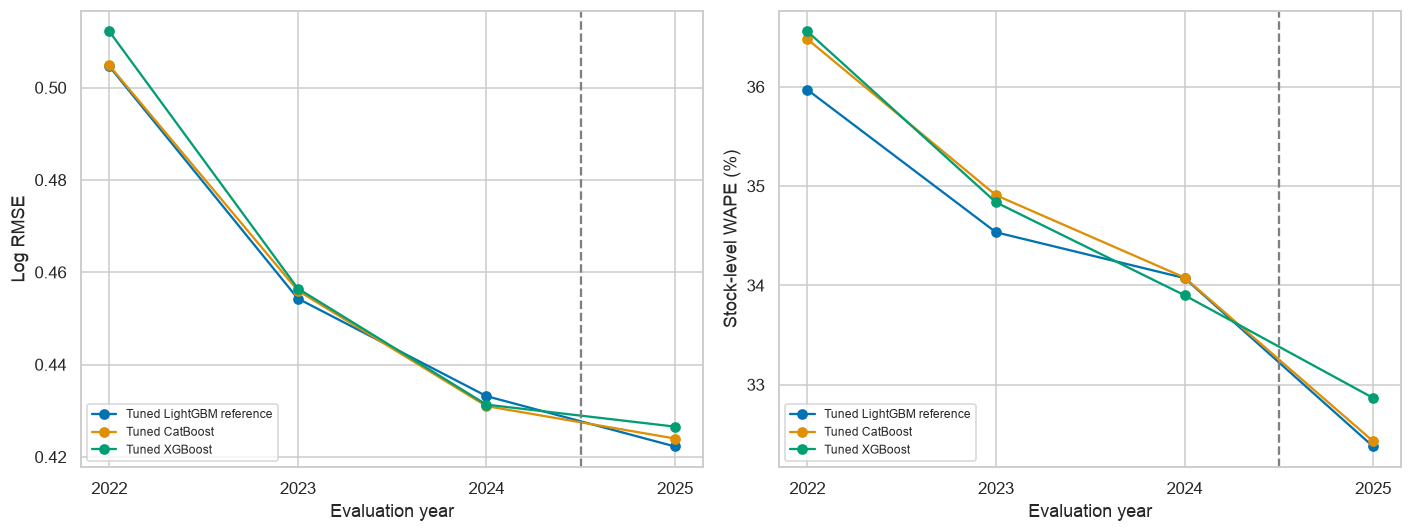

In [5]:
summary = annual_metrics[annual_metrics.year.isin(DEV)].groupby('family').agg(
    development_log_RMSE=('rmse_log', 'mean'), development_WAPE=('wape', 'mean'),
    development_bias=('aggregate_bias', 'mean'), development_log_MAE=('mae_log', 'mean'))
confirmation = annual_metrics[annual_metrics.year.eq(2025)].set_index('family')
summary['2025_log_RMSE'] = confirmation.rmse_log
summary['2025_WAPE'] = confirmation.wape
summary['2025_bias'] = confirmation.aggregate_bias
summary = summary.sort_values('development_log_RMSE')
summary.to_csv(RUN / 'summary.csv')
display(summary.rename(index=DISPLAY))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for family in FAMILIES:
    part = annual_metrics[annual_metrics.family.eq(family)].sort_values('year')
    axes[0].plot(part.year, part.rmse_log, marker='o', label=DISPLAY[family])
    axes[1].plot(part.year, 100 * part.wape, marker='o', label=DISPLAY[family])
for ax, metric in zip(axes, ['Log RMSE', 'Stock-level WAPE (%)']):
    ax.axvline(2024.5, color='grey', linestyle='--')
    ax.set(xticks=YEARS, xlabel='Evaluation year', ylabel=metric)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Tuning choices and convergence

The validation heatmaps display post-reconstruction log RMSE. They compare configurations within the same model family and historical fold. The convergence plot shows residual RMSE, the stopping metric. Its scale differs from the bounded post-reconstruction configuration-selection metric.

config_id  best_iteration  validation_log_rmse  fit_seconds
year family                                                               
2022 catboost          3             710               0.5701      31.9758
     xgboost           3             534               0.5706      23.3895
2023 catboost          3             747               0.5044      35.4653
     xgboost           1             554               0.5081      24.4241
2024 catboost          3             776               0.4551      38.9111
     xgboost           2            1336               0.4546      61.3429
2025 catboost          2             414               0.4294      21.8416
     xgboost           3             324               0.4309      17.6162

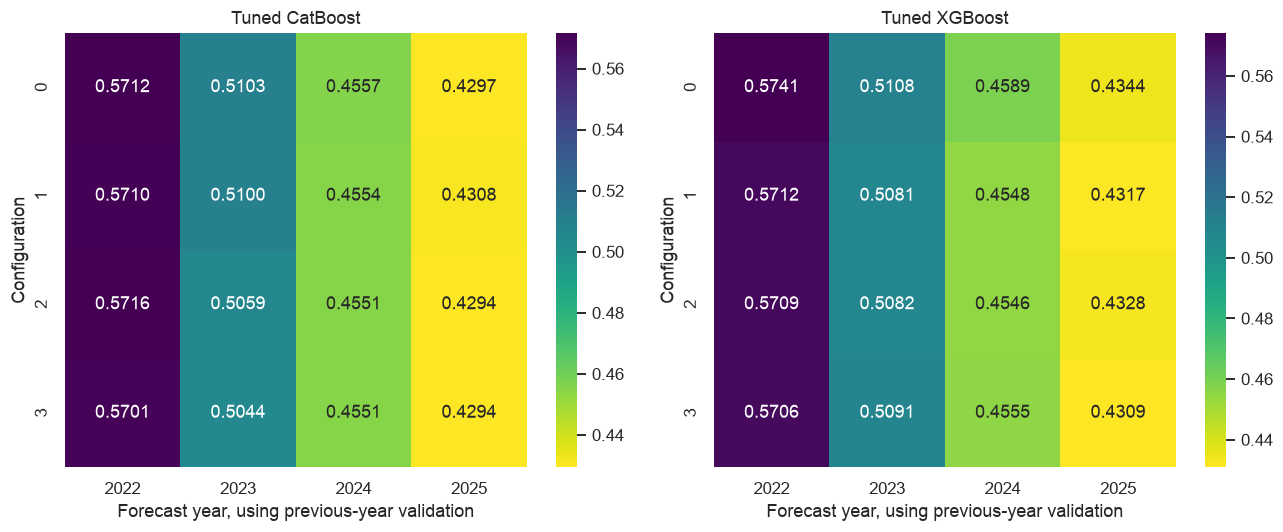

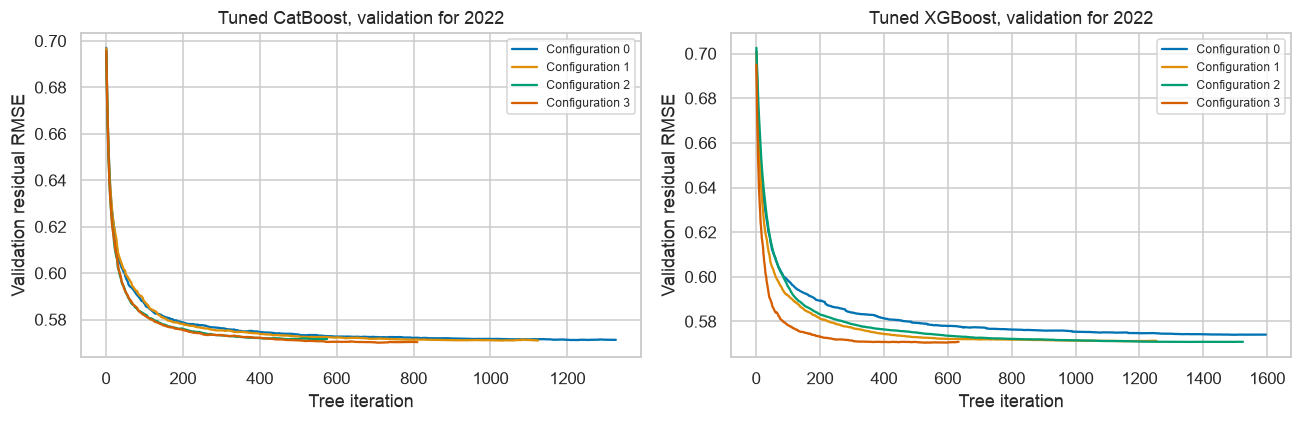

In [6]:
chosen = validation_metrics.loc[validation_metrics.groupby(['year', 'family']).validation_log_rmse.idxmin()]
display(chosen[['year', 'family', 'config_id', 'best_iteration', 'validation_log_rmse', 'fit_seconds']].set_index(['year', 'family']))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for family, ax in zip(['catboost', 'xgboost'], axes):
    table = validation_metrics[validation_metrics.family.eq(family)].pivot(index='config_id', columns='year', values='validation_log_rmse')
    sns.heatmap(table, annot=True, fmt='.4f', cmap='viridis_r', ax=ax)
    ax.set(title=DISPLAY[family], xlabel='Forecast year, using previous-year validation', ylabel='Configuration')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for family, ax in zip(['catboost', 'xgboost'], axes):
    cache = json.loads((RUN / f'validation/{family}_2022.json').read_text())
    for trial in cache['trials']:
        ax.plot(np.arange(1, len(trial['validation_residual_curve']) + 1), trial['validation_residual_curve'],
                label=f'Configuration {trial["config_id"]}')
    ax.set(title=f'{DISPLAY[family]}, validation for 2022', xlabel='Tree iteration', ylabel='Validation residual RMSE')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Paired uncertainty and the replacement rule

We retain the previous practical rule against the freshly fitted LightGBM reference. A challenger needs a mean development log-RMSE reduction of at least 0.002, no development year more than 0.002 worse, and a favorable 97.5th percentile bound for paired mean daily log-MAE differences. The legacy gate uses 2,000 independently resampled whole dates.

We also report direct log-RMSE and WAPE differences using 5,000 circular moving-block draws of 20 trading dates within each year. Each resampled date carries all stocks and both forecasts together, and each replicate recomputes the annual metrics before averaging years. These intervals preserve some serial dependence and match the headline metrics. They condition on fitted forecasts and omit refitting and accumulated model-selection uncertainty. The supplementary intervals are descriptive and do not change the frozen gate after seeing results.

In [7]:
from notebooks.evaluate_frozen_intraday import circular_weights
predictions = sql(f"SELECT * FROM read_parquet('{RUN}/predictions/boosters_*.parquet') ORDER BY date,permno")
assert not predictions.duplicated(['date', 'permno']).any()
assert len(predictions) == 1271378
predictions['year'] = predictions.date.dt.year
reference = 'lightgbm_reference'
points, intervals, gate_rows = [], [], []
annual_pivot = annual_metrics.pivot(index='family', columns='year', values='rmse_log')
for family in ['catboost', 'xgboost']:
    totals = predictions[['date', 'year', 'auction_volume']].copy()
    y = predictions.auction_volume.to_numpy(float)
    p = predictions[reference].to_numpy(float)
    q = predictions[family].to_numpy(float)
    totals['n'] = 1
    totals['sse_reference'] = (np.log1p(p) - np.log1p(y)) ** 2
    totals['sse_candidate'] = (np.log1p(q) - np.log1p(y)) ** 2
    totals['ae_reference'] = np.abs(p - y)
    totals['ae_candidate'] = np.abs(q - y)
    totals['log_mae_difference'] = np.abs(np.log1p(q) - np.log1p(y)) - np.abs(np.log1p(p) - np.log1p(y))
    daily = totals.groupby(['year', 'date']).agg(n=('n', 'sum'), actual=('auction_volume', 'sum'),
        sse_reference=('sse_reference', 'sum'), sse_candidate=('sse_candidate', 'sum'),
        ae_reference=('ae_reference', 'sum'), ae_candidate=('ae_candidate', 'sum'),
        log_mae_difference=('log_mae_difference', 'mean'))
    dev_differences = daily.loc[DEV].log_mae_difference.to_numpy()
    mean, low, high = cu.bootstrap_mean_interval(dev_differences, SEED + (0 if family == 'catboost' else 1), draws=2000)
    difference = annual_pivot.loc[family, DEV] - annual_pivot.loc[reference, DEV]
    gate_rows.append({'family': family, 'mean_log_RMSE_change': difference.mean(),
        'worst_annual_change': difference.max(), 'daily_log_MAE_change': mean, 'legacy_log_MAE_lower': low,
        'legacy_log_MAE_upper': high, 'practical_gain': difference.mean() <= -.002,
        'annual_stability': difference.max() <= .002, 'paired_log_MAE_favorable': high < 0,
        'passes_gate': bool(difference.mean() <= -.002 and difference.max() <= .002 and high < 0)})
    for period, years in [('development', DEV), ('confirmation', [2025])]:
        draws, observed = [], []
        for year in years:
            part = daily.loc[year]
            values = part[['n', 'actual', 'sse_reference', 'sse_candidate', 'ae_reference', 'ae_candidate']].to_numpy()
            weights = circular_weights(len(values), 20, 5000, SEED + year)
            t = weights @ values
            draws.append(np.column_stack([np.sqrt(t[:, 3] / t[:, 0]) - np.sqrt(t[:, 2] / t[:, 0]),
                                           (t[:, 5] - t[:, 4]) / t[:, 1]]))
            v = values.sum(axis=0)
            observed.append([np.sqrt(v[3] / v[0]) - np.sqrt(v[2] / v[0]), (v[5] - v[4]) / v[1]])
        draws = np.mean(draws, axis=0)
        observed = np.mean(observed, axis=0)
        limits = np.quantile(draws, [.025, .975], axis=0)
        for i, metric in enumerate(['log_RMSE', 'WAPE']):
            intervals.append({'family': family, 'period': period, 'metric': metric, 'difference': observed[i],
                              'ci_lower': limits[0, i], 'ci_upper': limits[1, i], 'block_dates': 20, 'draws': 5000})
gates = pd.DataFrame(gate_rows)
paired_intervals = pd.DataFrame(intervals)
gates.to_csv(RUN / 'selection.csv', index=False)
paired_intervals.to_csv(RUN / 'paired_intervals.csv', index=False)
display(gates.set_index('family'))
display(paired_intervals.set_index(['family', 'period', 'metric']))

,mean_log_RMSE_change,worst_annual_change,daily_log_MAE_change,legacy_log_MAE_lower,legacy_log_MAE_upper,practical_gain,annual_stability,paired_log_MAE_favorable,passes_gate
family,,,,,,,,,
catboost,-0.0001,0.0017,0.0012,-0.0001,0.0024,False,True,False,False
xgboost,0.0026,0.0076,0.0032,0.0018,0.0045,False,False,False,False


difference  ci_lower  ci_upper  block_dates  \
family   period       metric                                                  
catboost development  log_RMSE     -0.0001   -0.0019    0.0015           20   
                      WAPE          0.0030    0.0013    0.0046           20   
         confirmation log_RMSE      0.0017   -0.0006    0.0042           20   
                      WAPE          0.0005   -0.0021    0.0035           20   
xgboost  development  log_RMSE      0.0026    0.0007    0.0048           20   
                      WAPE          0.0024    0.0012    0.0036           20   
         confirmation log_RMSE      0.0043    0.0005    0.0082           20   
                      WAPE          0.0049    0.0009    0.0088           20   

                                draws  
family   period       metric           
catboost development  log_RMSE   5000  
                      WAPE       5000  
         confirmation log_RMSE   5000  
                      WAPE       5000  
xgboost  development  log_RMSE   5000  
                      WAPE       5000  
         confirmation log_RMSE   5000  
                      WAPE       5000

## Compare the CatBoost reproduction with Alisa's saved study

Both studies use the 61-feature recipe and the original four CatBoost configurations. This run uses a fresh, deterministic set of shared historical samples and the execution versions shown above. The table records the numerical differences. Its interpretation should use both development and confirmation years. A change in the model ranking is reported as a new result.

In [8]:
published = pd.read_csv(RESULTS / 'eda/16b_catboost_challenger/candidate_metrics.csv')
published = published[published.candidate.eq('catboost_61_ratios_large')].set_index('test_year')
cat_fresh = annual_metrics[annual_metrics.family.eq('catboost')].set_index('year')
reproduction = pd.DataFrame({'published_log_RMSE': published.rmse_log,
                            'fresh_log_RMSE': cat_fresh.rmse_log,
                            'published_WAPE': published.wape, 'fresh_WAPE': cat_fresh.wape})
reproduction['log_RMSE_change'] = reproduction.fresh_log_RMSE - reproduction.published_log_RMSE
reproduction.to_csv(RUN / 'catboost_reproduction.csv')
display(reproduction)

,published_log_RMSE,fresh_log_RMSE,published_WAPE,fresh_WAPE,log_RMSE_change
2022,0.5041,0.5048,0.3641,0.3648,0.0007
2023,0.4563,0.4560,0.3497,0.3491,-0.0003
2024,0.4306,0.4310,0.3394,0.3408,0.0004
2025,0.4229,0.4240,0.3219,0.3243,0.0010


## Segment diagnostics and model dependence

Segments are fixed diagnostic groups, using prior-close size percentiles, history counts and disjoint event flags. Actual-volume tails are retrospective labels. The charts summarize how error reductions differ across groups and how similar the model errors remain. These are exploratory diagnostics.

Feature-importance methods differ across the libraries. Values are normalized within each fitted model and should be interpreted within a family. They are descriptive and can share signal among correlated inputs.

rmse_log   wape  aggregate_bias
dimension segment          family                                             
event     month_end        catboost              0.6437 0.4680         -0.2519
                           lightgbm_reference    0.6498 0.4642         -0.2870
                           xgboost               0.6498 0.4652         -0.2730
          monthly_expiry   catboost              0.5419 0.3750         -0.1349
                           lightgbm_reference    0.5419 0.3750         -0.1349
                           xgboost               0.5446 0.3753         -0.1370
          quarterly_expiry catboost              0.7534 0.5262         -0.3234
                           lightgbm_reference    0.7550 0.5215         -0.3155
                           xgboost               0.7605 0.5242         -0.3168
          regular          catboost              0.4423 0.3116         -0.1039
                           lightgbm_reference    0.4419 0.3088         -0.1135
                           xgboost               0.4446 0.3114         -0.1077
size      large            catboost              0.3930 0.3270         -0.1211
                           lightgbm_reference    0.3922 0.3238         -0.1330
                           xgboost               0.3941 0.3255         -0.1274
          mid              catboost              0.4259 0.3885         -0.1748
                           lightgbm_reference    0.4257 0.3859         -0.1803
                           xgboost               0.4282 0.3895         -0.1728
          small            catboost              0.5689 0.4469         -0.2290
                           lightgbm_reference    0.5699 0.4442         -0.2312
                           xgboost               0.5734 0.4500         -0.2306

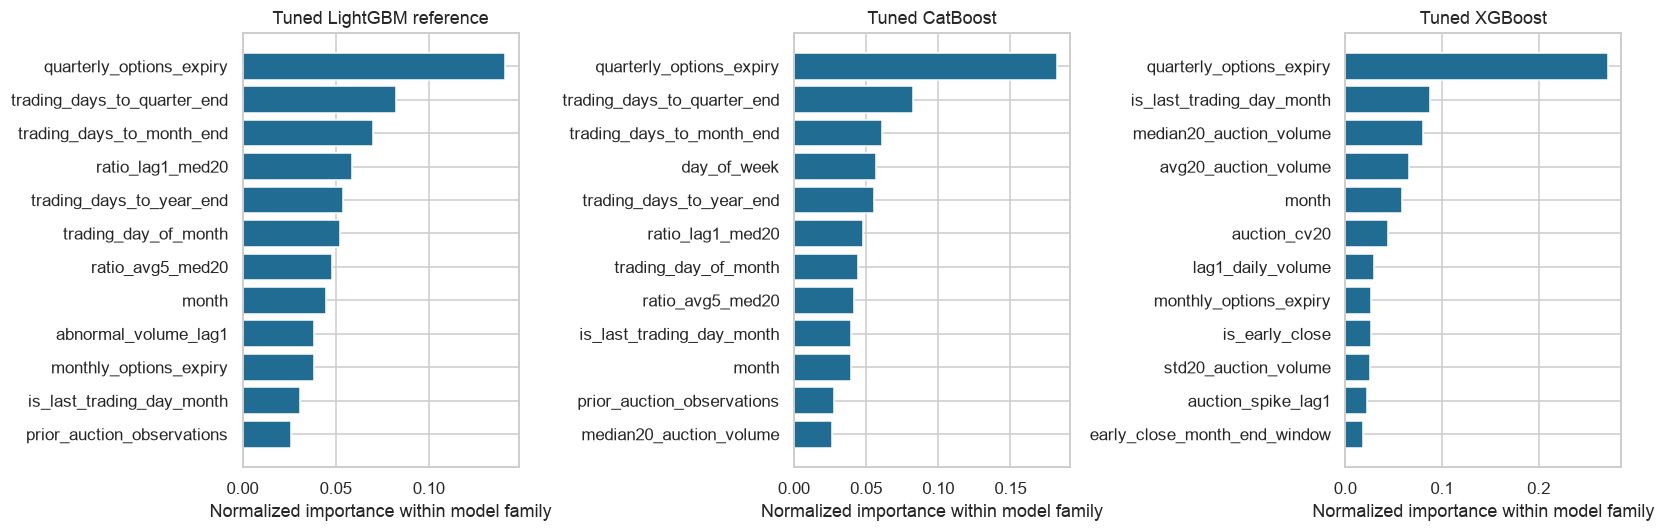

,Tuned LightGBM reference,Tuned CatBoost,Tuned XGBoost
Tuned LightGBM reference,1.0000,0.9838,0.9835
Tuned CatBoost,0.9838,1.0000,0.9826
Tuned XGBoost,0.9835,0.9826,1.0000


In [9]:
segment_rows = []
predictions['event'] = np.select([predictions.quarterly_options_expiry.fillna(False),
                                  predictions.monthly_options_expiry.fillna(False),
                                  predictions.is_last_trading_day_month.fillna(False)],
                                 ['quarterly_expiry', 'monthly_expiry', 'month_end'], default='regular')
predictions['size_group'] = pd.cut(predictions.size_percentile, [-np.inf, 1/3, 2/3, np.inf], labels=['small', 'mid', 'large'])
for (year, group), part in predictions.groupby(['year', 'event']):
    for family in FAMILIES:
        segment_rows.append({'year': year, 'dimension': 'event', 'segment': group, 'family': family,
                             **forecast_metrics(part.auction_volume, part[family])})
for (year, group), part in predictions.groupby(['year', 'size_group'], observed=True):
    for family in FAMILIES:
        segment_rows.append({'year': year, 'dimension': 'size', 'segment': str(group), 'family': family,
                             **forecast_metrics(part.auction_volume, part[family])})
segments = pd.DataFrame(segment_rows)
segments.to_csv(RUN / 'segment_metrics.csv', index=False)
segment_summary = (segments[segments.year.isin(DEV)].groupby(['dimension', 'segment', 'family'])
                   [['rmse_log', 'wape', 'aggregate_bias']].mean())
display(segment_summary)
errors = pd.DataFrame({family: np.log1p(predictions.loc[predictions.year.isin(DEV), family])
                      - predictions.loc[predictions.year.isin(DEV), 'log1p_auction_volume'] for family in FAMILIES})
error_correlation = errors.corr()
error_correlation.to_csv(RUN / 'error_correlation.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for family, ax in zip(FAMILIES, axes):
    top = (importance[importance.family.eq(family) & importance.year.isin(DEV)]
           .groupby('feature').importance_share.mean().nlargest(12).sort_values())
    ax.barh(top.index, top.values, color='#216c93')
    ax.set(title=DISPLAY[family], xlabel='Normalized importance within model family')
plt.tight_layout(); plt.show()
display(error_correlation.rename(index=DISPLAY, columns=DISPLAY))

## Checkpoint 4 decision

The following conclusion is generated from the complete fresh comparison. The published CatBoost result remains visible above. This checkpoint addresses the two requested booster families. The previous regime and neural-network studies remain in the original research notebooks.

The fresh development scores are **0.46394 for CatBoost**, **0.46402 for LightGBM** and **0.46665 for XGBoost**. CatBoost's log-RMSE difference versus LightGBM is −0.00008, with a 20-date interval of approximately −0.00194 to +0.00152. Its WAPE is higher by **0.296 percentage points**, with an interval of +0.134 to +0.455 points. Its aggregate bias is less negative, illustrating a metric tradeoff.

XGBoost's development log RMSE is higher by **0.00263**, with an interval of approximately +0.00065 to +0.00479. Its 2022 deterioration of **0.00757** also exceeds the annual-stability tolerance. In 2025 LightGBM retains the lowest log RMSE and WAPE among these three fresh fits.

The CatBoost development result differs from Alisa's published score by approximately **+0.00027 log RMSE**, and both studies retain an effective tie with LightGBM. Its 2025 log RMSE differs by approximately +0.00105. The main conclusion remains consistent with her study. XGBoost is a new result under the four declared settings and historical procedure.


In [10]:
eligible = gates[gates.passes_gate].family.tolist()
if eligible:
    selected_family = summary.loc[eligible].development_log_RMSE.idxmin()
    explanation = f'{DISPLAY[selected_family]} meets the frozen practical, annual stability and paired log-MAE criteria against the fresh LightGBM reference.'
else:
    selected_family = 'lightgbm_reference'
    explanation = 'Neither challenger meets all frozen replacement criteria. Retain the tuned LightGBM recipe as the main daily model.'
smallest = summary.development_log_RMSE.idxmin()
conclusion = {'selected_family': selected_family, 'lowest_development_point_estimate': smallest,
              'challengers_passing_gate': eligible, 'explanation': explanation,
              'evaluation_rows': len(predictions), 'plan_hash': PLAN_HASH}
write_json(RUN / 'conclusion.json', conclusion)
display(Markdown(f'**{explanation}**'))
display(Markdown(f'The lowest development point estimate is {DISPLAY[smallest]} at '
                 f'{summary.loc[smallest, "development_log_RMSE"]:.5f} log RMSE. '
                 'Review WAPE, bias, individual years and the supplementary direct-metric intervals alongside that ranking.'))

**Neither challenger meets all frozen replacement criteria. Retain the tuned LightGBM recipe as the main daily model.**

The lowest development point estimate is Tuned CatBoost at 0.46394 log RMSE. Review WAPE, bias, individual years and the supplementary direct-metric intervals alongside that ranking.

## Verification and reproducibility

The study retains complete matched forecasts for 1,271,378 stock-days, 12 fitted models, historical preprocessing and bounds, realized fitting-sample keys, all 32 validation trials and the frozen plan. The final cell recomputes each annual score from the written forecasts, checks metric agreement and records the completed-run status.

In [11]:
for row in annual_metrics.itertuples():
    frame = predictions[predictions.year.eq(row.year)]
    result = forecast_metrics(frame.auction_volume, frame[row.family])
    for metric in ['observations', 'rmse_log', 'wape', 'aggregate_bias', 'mae_log']:
        np.testing.assert_allclose(result[metric], getattr(row, metric), rtol=1e-10, atol=1e-10)
# Reconcile the written forecasts with independent SQL formulas as well.
for row in annual_metrics.itertuples():
    path = RUN / f'predictions/boosters_{row.year}.parquet'
    family = row.family
    independent = sql(f"""
        SELECT count(*) AS observations,
               sqrt(avg(pow(ln(1 + {family}) - log1p_auction_volume, 2))) AS rmse_log,
               sum(abs({family} - auction_volume)) / sum(auction_volume) AS wape,
               sum({family}) / sum(auction_volume) - 1 AS aggregate_bias
        FROM read_parquet('{path}')
    """).iloc[0]
    np.testing.assert_allclose(independent.to_numpy(float),
        [row.observations, row.rmse_log, row.wape, row.aggregate_bias], rtol=1e-10, atol=1e-10)
assert len(validation_metrics) == 32
assert len(sample_manifest) == 16
assert len(annual_metrics) == 12
assert len(predictions) == 1271378
assert all((RUN / f'models/{family}_{year}{suffix}').is_file()
           for year in YEARS for family, suffix in [('lightgbm_reference', '.txt'), ('catboost', '.cbm'), ('xgboost', '.ubj')])
assert validation_checks.passed.all()
write_json(RUN / 'verification_summary.json', {'status': 'passed', 'plan_hash': PLAN_HASH,
           'stock_days': len(predictions), 'model_years': 12, 'validation_trials': 32,
           'checks': validation_checks.to_dict('records'), 'annual_metric_reconciliation': True, 'independent_sql_metric_reconciliation': True})
progress('Checkpoint 4 complete: all four years, 12 saved models, 32 tuning trials and metric verification passed.')
cu.con.close()
con.close()
work.cleanup()

2026-11-17T21:55:11.338429+00:00 Checkpoint 4 complete: all four years, 12 saved models, 32 tuning trials and metric verification passed.
